# Science case: stellar metallicity characterisation with the Bench

At R ~ 1800 the Bench sample configuration is LAMOST-like (LAMOST LRS is R ~ 1800 over
370-900 nm). Survey pipelines at that resolution deliver [Fe/H] to ~0.1 dex for FGK stars once the
SNR per *pixel* exceeds ~20-30 (LAMOST LASP: Wu et al. 2014, Luo et al. 2015; SEGUE SSPP: ~0.11
dex at SNR >= 50, Lee et al. 2008), with a ~0.1 dex floor; ~0.05 dex is reached only by data-driven
methods trained on high-resolution labels (Ho et al. 2017; Xiang et al. 2019) at SNR > 50. The ETC
works per *resel* (2.2 pixels here), so SNR 20/pixel is ~30/resel. The 412-686 nm window carries
the Ca I 422.7, G band, Fe/Mg b (516-519) and Na D (589) features that drive the sensitivity.

**Assumptions used here** (knobs, change freely):

* SNR per resel targets: 30 (~0.1 dex, LAMOST-like) and 75 (what data-driven ~0.05 dex methods need).
* Metric wavelength window: 500-560 nm (Mg b region).
* Stars: 5800 K (G dwarf), 4500 K (K dwarf), 3500 K (M dwarf) blackbodies normalised in V. The M
  dwarf is included only for the SNR budget: M-dwarf metallicities at R ~ 1800 do not come from
  Mg b / Na D and LAMOST M-dwarf [Fe/H] are poor; treat that row as a throughput number only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude
try:
    plt.style.use('gks')
except OSError:
    pass

In [2]:
bench = LFASTETC("bench_r1800", n_telescopes=20)
stars = {"G dwarf 5800 K": 5800, "K dwarf 4500 K": 4500, "M dwarf 3500 K": 3500}
mags = np.linspace(9, 20, 45)
window = (500, 560)

## Exposure time to reach the SNR thresholds

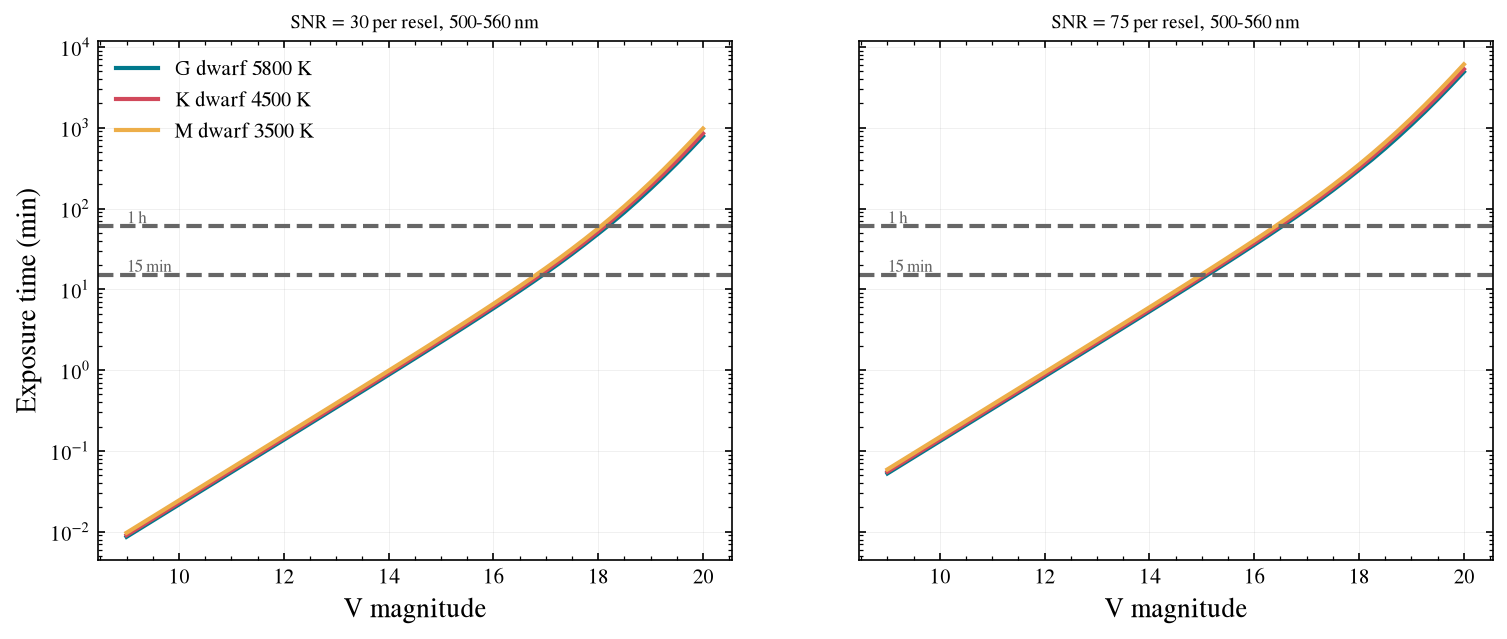

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, snr_t in zip(axes, (30, 75)):
    for label, teff in stars.items():
        t = bench.exptime_vs_mag(Source.blackbody(teff, 0, "V"), mags, snr=snr_t, wavelength=window)
        ax.plot(mags, t/60, label=label)
    ax.set_yscale('log'); ax.set_xlabel("V magnitude"); ax.set_title(f"SNR = {snr_t} per resel, 500-560 nm", fontsize=9)
    for h, txt in ((15, "15 min"), (60, "1 h")):
        ax.axhline(h, color='0.4', ls='--'); ax.text(mags[0], h*1.1, txt, fontsize=8, color='0.4')
axes[0].set_ylabel("Exposure time (min)"); axes[0].legend();

## Survey depth: limiting magnitude per exposure length

In [4]:
for exp in (300, 900, 3600):
    row = []
    for label, teff in stars.items():
        m30 = bench.limiting_magnitude(Source.blackbody(teff, 0, "V"), exp, 30, wavelength=window)
        m75 = bench.limiting_magnitude(Source.blackbody(teff, 0, "V"), exp, 75, wavelength=window)
        row.append(f"{label.split()[0]}: V<{m30:.1f} (SNR30) / V<{m75:.1f} (SNR75)")
    print(f"{exp:5d} s  " + " | ".join(row))

  300 s  G: V<15.8 (SNR30) / V<13.9 (SNR75) | K: V<15.8 (SNR30) / V<13.9 (SNR75) | M: V<15.7 (SNR30) / V<13.8 (SNR75)
  900 s  G: V<16.9 (SNR30) / V<15.1 (SNR75) | K: V<16.9 (SNR30) / V<15.0 (SNR75) | M: V<16.8 (SNR30) / V<15.0 (SNR75)
 3600 s  G: V<18.2 (SNR30) / V<16.5 (SNR75) | K: V<18.1 (SNR30) / V<16.5 (SNR75) | M: V<18.0 (SNR30) / V<16.4 (SNR75)


## Where does the information come from? SNR across the band

Metallicity indicators are spread over the whole window; the SNR per resel is far from flat
because the throughput and the stellar SED both change strongly across 412-688 nm.

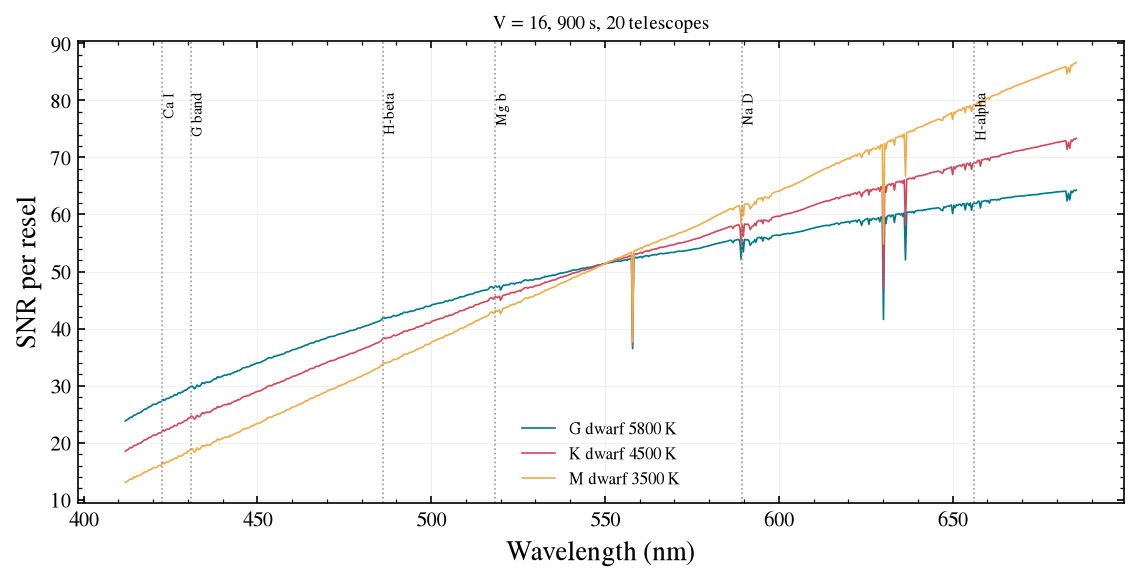

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for label, teff in stars.items():
    r = bench.snr(Source.blackbody(teff, 16, "V"), exptime=900)
    ax.plot(r.wavelength, r.snr, lw=0.8, label=label)
for w, name in ((422.7, "Ca I"), (430.8, "G band"), (486.1, "H-beta"), (518.4, "Mg b"), (589.3, "Na D"), (656.3, "H-alpha")):
    ax.axvline(w, color='0.6', ls=':', lw=0.8); ax.text(w, ax.get_ylim()[1]*0.9 if ax.get_ylim()[1]>0 else 1, name, fontsize=7, rotation=90, va='top')
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("SNR per resel"); ax.set_title("V = 16, 900 s, 20 telescopes", fontsize=9)
ax.legend(fontsize=8);

## Survey throughput

Number of stars per 8 h night as a function of magnitude for the SNR = 30 target
(per-target overhead of 2 min assumed; 1 target at a time since all fibers point at one star).

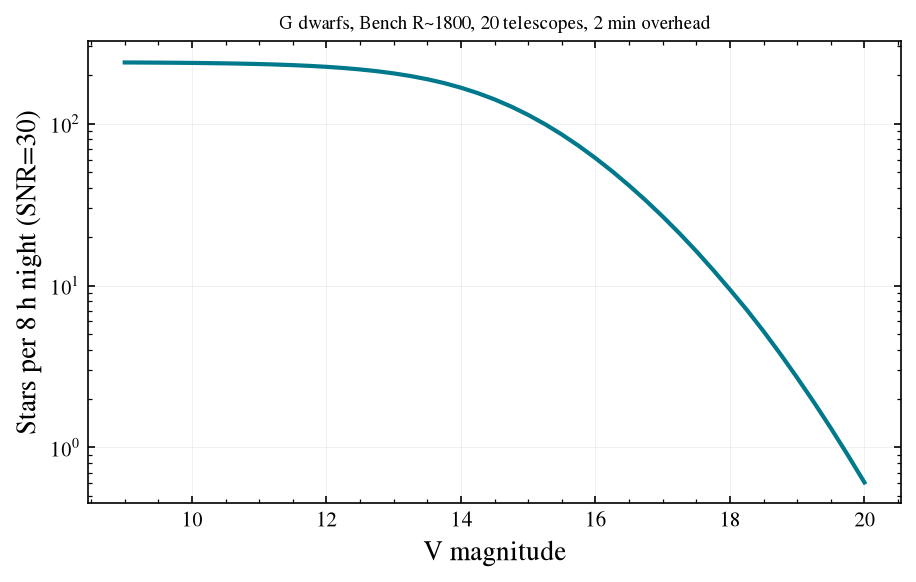

In [6]:
overhead = 120.0
t = bench.exptime_vs_mag(Source.blackbody(5800, 0, "V"), mags, snr=30, wavelength=window)
n_per_night = 8*3600 / (t + overhead)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mags, n_per_night)
ax.set_yscale('log'); ax.set_xlabel("V magnitude"); ax.set_ylabel("Stars per 8 h night (SNR=30)")
ax.set_title("G dwarfs, Bench R~1800, 20 telescopes, 2 min overhead", fontsize=9);

## Effect of the array size on survey depth at fixed SNR = 30 in 15 min

In [7]:
ns = [5, 10, 20, 40, 80]
for n in ns:
    e = LFASTETC("bench_r1800", n_telescopes=n)
    print(f"N={n:3d}: V_lim(SNR=30, 15 min) = {e.limiting_magnitude(Source.blackbody(5800,0,'V'), 900, 30, wavelength=window):.2f}")

N=  5: V_lim(SNR=30, 15 min) = 15.54
N= 10: V_lim(SNR=30, 15 min) = 16.26
N= 20: V_lim(SNR=30, 15 min) = 16.94
N= 40: V_lim(SNR=30, 15 min) = 17.58
N= 80: V_lim(SNR=30, 15 min) = 18.17
